# Lab 07: A First Machine Learning Species Distribution Model

## BIO597 Spatial Analysis of Biodiversity

Last week we built a suitability curve ourselves. This week we will use a **random forest** to learn a relationship between amphibian records and climate.

A decision tree asks a series of questions, such as “Is annual precipitation greater than 1,000 mm?” A random forest combines many trees. We will use `RandomForestRegressor` to produce a continuous suitability score.

We will:

* prepare presence and background data with all available climate variables
* train and test a model using annual mean temperature, as we did last week
* add two precipitation variables and compare prediction error
* make a suitability map and look at variable importance


## 1. Import packages

Most of these packages are familiar. `scikit-learn` adds tools for splitting data, fitting a random forest, and checking predictions.

Run this notebook from the `docs/labs` directory, as in earlier labs. If needed, install scikit-learn with `%pip install scikit-learn` in a new cell.


In [4]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [5]:
pip install rioxarray

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.1/39.1 MB 11.8 MB/s  0:00:03m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 16.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [rioxarray]/4 [xarray]o]
Note: you may need to restart the kernel to use updated packages.


In [6]:
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import rioxarray
import xarray as xr

from sklearn.ensemble import RandomForestRegressor 
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split


## 2. Load the prepared data

The GeoJSON contains amphibian records and their climate values. The NetCDF contains climate layers for Maine. We do not need to download or clip rasters today.


In [7]:
amphibians = gpd.read_file("../data/amphibians+bioclim.geojson")
climate = xr.open_dataset("../data/maine_bioclim.nc")

amphibians["species"].value_counts().head(12)


species
Pseudacris crucifer          1722
Aquarana clamitans           1656
Anaxyrus americanus          1581
Boreorana sylvatica          1522
Lithobates catesbeianus      1451
Ambystoma maculatum          1214
Plethodon cinereus           1125
Lithobates palustris         1007
Dryophytes versicolor         714
Notophthalmus viridescens     573
Lithobates pipiens            325
Hemidactylium scutatum        226
Name: count, dtype: int64

## 3. Choose a species

We will use the wood frog, **Boreorana sylvatica**, again. Keep records with coordinate uncertainty below 100 m.


Number of records: 1119


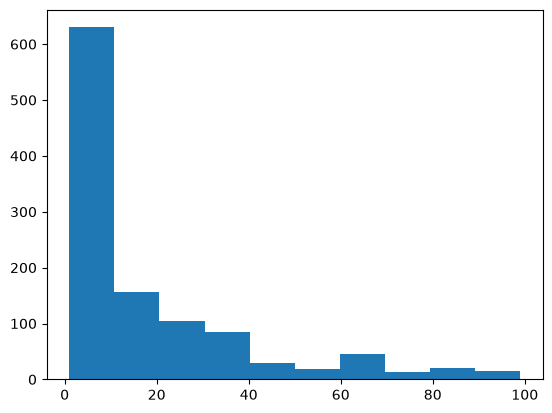

In [8]:
target_species = "Boreorana sylvatica"
presence = amphibians[amphibians["species"] == target_species].copy()
presence = presence[presence["coordinateUncertaintyInMeters"] < 100].copy()

print("Number of records:", len(presence))

# Inspect the distribution of coordinate uncertainty
_ = plt.hist(presence["coordinateUncertaintyInMeters"])

In [9]:
presence

,gbifID,species,decimalLongitude,decimalLatitude,coordinateUncertaintyInMeters,year,bio_1,bio_10,bio_11,bio_2,...,bio_6,bio_4,bio_15,bio_14,bio_5,bio_8,bio_19,bio_18,bio_9,geometry
4,6520670325,Boreorana sylvatica,-70.411203,43.454942,4.0,2025.0,7.865667,18.892000,-3.424000,10.690000,...,-10.080,900.472961,13.864340,80.0,25.896000,3.824667,287.0,244.0,18.892000,POINT (-70.4112 43.45494)
12,6520588534,Boreorana sylvatica,-69.881597,44.539065,4.0,2026.0,6.616833,18.892000,-6.432000,11.515000,...,-14.268,1021.611206,10.415270,68.0,26.452000,2.436667,243.0,276.0,-5.394667,POINT (-69.8816 44.53906)
31,6520186899,Boreorana sylvatica,-70.166047,44.104725,14.0,2026.0,7.135167,19.248667,-5.605333,11.046333,...,-12.684,1000.152649,11.191950,79.0,26.507999,2.561333,280.0,260.0,18.355333,POINT (-70.16605 44.10472)
35,6520157815,Boreorana sylvatica,-69.835878,44.602813,12.0,2026.0,6.411000,18.755333,-6.721334,11.700000,...,-14.692,1028.518188,10.817848,67.0,26.364000,2.182667,240.0,279.0,-5.682667,POINT (-69.83588 44.60281)
76,6519546366,Boreorana sylvatica,-70.549422,43.341447,4.0,2026.0,8.045667,19.328667,-3.490000,11.253333,...,-10.304,919.454346,13.353818,81.0,26.708000,3.832000,280.0,248.0,19.328667,POINT (-70.54942 43.34145)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13642,686723549,Boreorana sylvatica,-70.910300,43.534200,1.0,1932.0,7.148334,18.975334,-5.236000,12.456667,...,-12.944,975.476379,12.493836,87.0,27.035999,2.724667,292.0,279.0,18.062666,POINT (-70.9103 43.5342)
13643,686723547,Boreorana sylvatica,-70.910300,43.534200,1.0,1932.0,7.148334,18.975334,-5.236000,12.456667,...,-12.944,975.476379,12.493836,87.0,27.035999,2.724667,292.0,279.0,18.062666,POINT (-70.9103 43.5342)
13644,686723545,Boreorana sylvatica,-70.910300,43.534200,1.0,1932.0,7.148334,18.975334,-5.236000,12.456667,...,-12.944,975.476379,12.493836,87.0,27.035999,2.724667,292.0,279.0,18.062666,POINT (-70.9103 43.5342)
13645,686723544,Boreorana sylvatica,-70.910300,43.534200,1.0,1932.0,7.148334,18.975334,-5.236000,12.456667,...,-12.944,975.476379,12.493836,87.0,27.035999,2.724667,292.0,279.0,18.062666,POINT (-70.9103 43.5342)


In [12]:
climate

<xarray.Dataset> Size: 2MB
Dimensions:      (y: 109, x: 101)
Coordinates:
  * y            (y) float64 872B 47.48 47.44 47.4 47.35 ... 43.06 43.02 42.98
  * x            (x) float64 808B -71.1 -71.06 -71.02 ... -67.02 -66.98 -66.94
    band         int32 4B 1
Data variables: (12/20)
    bio_1        (y, x) float64 88kB nan nan nan nan nan ... nan nan nan nan nan
    bio_10       (y, x) float64 88kB nan nan nan nan nan ... nan nan nan nan nan
    bio_11       (y, x) float64 88kB nan nan nan nan nan ... nan nan nan nan nan
    bio_2        (y, x) float64 88kB nan nan nan nan nan ... nan nan nan nan nan
    bio_13       (y, x) float64 88kB nan nan nan nan nan ... nan nan nan nan nan
    bio_12       (y, x) float64 88kB nan nan nan nan nan ... nan nan nan nan nan
    ...           ...
    bio_5        (y, x) float64 88kB nan nan nan nan nan ... nan nan nan nan nan
    bio_8        (y, x) float64 88kB nan nan nan nan nan ... nan nan nan nan nan
    bio_19       (y, x) float64 88kB nan nan nan nan nan ... nan nan nan nan nan
    bio_18       (y, x) float64 88kB nan nan nan nan nan ... nan nan nan nan nan
    bio_9        (y, x) float64 88kB nan nan nan nan nan ... nan nan nan nan nan
    spatial_ref  int32 4B ...
Attributes:
    AREA_OR_POINT:       Area
    STATISTICS_MAXIMUM:  31.166666030884
    STATISTICS_MEAN:     nan
    STATISTICS_MINIMUM:  -54.759166717529
    STATISTICS_STDDEV:   nan
    scale_factor:        1.0
    add_offset:          0.0

## 4. Load all climate predictors

A **predictor** is a variable we use to help predict the response. Keep all 19 bioclimatic variables available during data preparation. We will choose which ones the model uses in step 9.

The names run from `bio_1` through `bio_19`. The code below makes that list; `range(1, 20)` stops before 20.


In [10]:
climate_variables = ["bio_" + str(number) for number in range(1, 20)]

presence[climate_variables].head()

,bio_1,bio_2,bio_3,bio_4,bio_5,bio_6,bio_7,bio_8,bio_9,bio_10,bio_11,bio_12,bio_13,bio_14,bio_15,bio_16,bio_17,bio_18,bio_19
4,7.865667,10.690000,29.714254,900.472961,25.896000,-10.080,35.975998,3.824667,18.892000,18.892000,-3.424000,1146.0,122.0,80.0,13.864340,336.0,244.0,244.0,287.0
12,6.616833,11.515000,28.278488,1021.611206,26.452000,-14.268,40.720001,2.436667,-5.394667,18.892000,-6.432000,1088.0,105.0,68.0,10.415270,298.0,238.0,276.0,243.0
31,7.135167,11.046333,28.185173,1000.152649,26.507999,-12.684,39.192001,2.561333,18.355333,19.248667,-5.605333,1144.0,112.0,79.0,11.191950,322.0,253.0,260.0,280.0
35,6.411000,11.700000,28.497662,1028.518188,26.364000,-14.692,41.056000,2.182667,-5.682667,18.755333,-6.721334,1080.0,104.0,67.0,10.817848,296.0,231.0,279.0,240.0
76,8.045667,11.253333,30.404554,919.454346,26.708000,-10.304,37.012001,3.832000,19.328667,19.328667,-3.490000,1134.0,123.0,81.0,13.353818,333.0,248.0,248.0,280.0


## 5. Make a table of Maine's climate cells

Scikit-learn works with tables. Here, each row is one raster cell, with all 19 climate variables available as columns. Keep coordinates for mapping and remove cells with missing climate values. We will use this same table for both models so that changing predictors does not change the available cells.


In [13]:
grid = climate[climate_variables].to_dataframe().reset_index()
grid = grid[["x", "y"] + climate_variables]
grid = grid.dropna(subset=climate_variables)
grid.head()

# need to convert the climate data to a dataframe

,x,y,bio_1,bio_2,bio_3,bio_4,bio_5,bio_6,bio_7,bio_8,...,bio_10,bio_11,bio_12,bio_13,bio_14,bio_15,bio_16,bio_17,bio_18,bio_19
146,-69.229167,47.437500,2.610167,10.487667,24.623560,1133.966675,23.148001,-19.444000,42.592003,16.066000,...,16.066000,-12.065333,1093.0,110.0,67.0,13.786905,317.0,227.0,317.0,231.0
147,-69.187500,47.437500,2.620167,10.551667,24.738974,1134.299316,23.200001,-19.452000,42.652000,16.072001,...,16.072001,-12.078667,1080.0,110.0,66.0,14.227962,316.0,223.0,316.0,228.0
148,-69.145833,47.437500,2.786333,10.607333,24.855499,1130.561035,23.344000,-19.332001,42.676003,16.170000,...,16.170000,-11.888667,1043.0,108.0,63.0,14.921009,307.0,211.0,307.0,222.0
246,-69.270833,47.395833,2.161333,10.447333,24.595850,1134.809448,22.668001,-19.808001,42.476002,15.676667,...,15.676667,-12.473333,1130.0,116.0,69.0,14.441315,332.0,233.0,332.0,237.0
247,-69.229167,47.395833,2.441500,10.566333,24.831577,1130.958252,22.968000,-19.584000,42.552002,15.872000,...,15.872000,-12.190666,1099.0,113.0,67.0,14.589335,323.0,226.0,323.0,231.0


## 6. Simplify the presence data to only retain bioclim variables

The bioclim variables will be the 'features' and we will create a new column
called 'observed' which will be the 'target' for learning and prediction.

Cells containing a record get **1**. Other cells get **0** and form our background pool.

In [14]:
presence_data = presence[climate_variables]
presence_data["observed"] = 1
presence_data

,bio_1,bio_2,bio_3,bio_4,bio_5,bio_6,bio_7,bio_8,bio_9,bio_10,bio_11,bio_12,bio_13,bio_14,bio_15,bio_16,bio_17,bio_18,bio_19,observed
4,7.865667,10.690000,29.714254,900.472961,25.896000,-10.080,35.975998,3.824667,18.892000,18.892000,-3.424000,1146.0,122.0,80.0,13.864340,336.0,244.0,244.0,287.0,1
12,6.616833,11.515000,28.278488,1021.611206,26.452000,-14.268,40.720001,2.436667,-5.394667,18.892000,-6.432000,1088.0,105.0,68.0,10.415270,298.0,238.0,276.0,243.0,1
31,7.135167,11.046333,28.185173,1000.152649,26.507999,-12.684,39.192001,2.561333,18.355333,19.248667,-5.605333,1144.0,112.0,79.0,11.191950,322.0,253.0,260.0,280.0,1
35,6.411000,11.700000,28.497662,1028.518188,26.364000,-14.692,41.056000,2.182667,-5.682667,18.755333,-6.721334,1080.0,104.0,67.0,10.817848,296.0,231.0,279.0,240.0,1
76,8.045667,11.253333,30.404554,919.454346,26.708000,-10.304,37.012001,3.832000,19.328667,19.328667,-3.490000,1134.0,123.0,81.0,13.353818,333.0,248.0,248.0,280.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13642,7.148334,12.456667,31.157246,975.476379,27.035999,-12.944,39.980000,2.724667,18.062666,18.975334,-5.236000,1203.0,132.0,87.0,12.493836,349.0,272.0,279.0,292.0,1
13643,7.148334,12.456667,31.157246,975.476379,27.035999,-12.944,39.980000,2.724667,18.062666,18.975334,-5.236000,1203.0,132.0,87.0,12.493836,349.0,272.0,279.0,292.0,1
13644,7.148334,12.456667,31.157246,975.476379,27.035999,-12.944,39.980000,2.724667,18.062666,18.975334,-5.236000,1203.0,132.0,87.0,12.493836,349.0,272.0,279.0,292.0,1
13645,7.148334,12.456667,31.157246,975.476379,27.035999,-12.944,39.980000,2.724667,18.062666,18.975334,-5.236000,1203.0,132.0,87.0,12.493836,349.0,272.0,279.0,292.0,1


## 7. Sample background cells

**A background cell is not a confirmed absence.** It is a place without a record in this dataset. We are learning to distinguish recorded environments from background environments, not estimating abundance or the true probability of occurrence.

Use the same number of background cells as presence cells. `random_state` makes the random sample repeatable. The climate values for both groups come from the same raster table.


In [21]:
background = grid.sample(n=len(presence_data), random_state=42)
background["observed"] = 0

model_data = pd.concat([presence_data, background], ignore_index=True)

model_data["observed"].value_counts()

# you want an equal number for machine learning

observed
1    1119
0    1119
Name: count, dtype: int64

## 8. Define predictors and response

In scikit-learn, **`X`** usually means the predictor table and **`y`** means the response we want to predict. Here, `y` contains our 1/0 presence/background labels. Coordinates stay out of the predictor table.

Start with just **`bio_1`: annual mean temperature (°C)**, the same variable used last week. We have all climate variables available, but `features` chooses which columns the model actually uses. Later, we will expand this list to three predictors.


In [22]:
features = ["bio_1"]
X = model_data[features]
y = model_data["observed"]

X.head()

# standard machine learning to call X the rpedictor table and Y as the response


,bio_1
0,7.865667
1,6.616833
2,7.135167
3,6.411000
4,8.045667


## 9. Set aside test data

A model can fit familiar data well and still predict new data poorly. We will use 75% of the cells to **train** the model and hold back 25% to **test** it.

Split the full modeling table once, then select our predictor columns. This keeps the same training and test cells available when we add more predictors. `stratify=y` keeps similar proportions of presence and background in the two groups.


In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=597, # seeds the random number generator so the results we get are going to be reproducible
)

print("Training cells:", len(X_train))
print("Test cells:", len(X_test))


Training cells: 1678
Test cells: 560


## 11. Train a random forest

`n_estimators=100` means 100 trees. `min_samples_leaf=5` prevents each tree from making its final groups too small. `.fit()` learns the relationship between climate and our labels.

Each tree predicts an average of its training labels. Averaging across trees gives a score between 0 and 1, which we will call **relative suitability**. Its meaning depends on how we chose the background data.


In [24]:
model = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=5,
    random_state=42,
)
model.fit(X_train, y_train)


,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

## 12. Predict the withheld cells

`.predict()` applies the learned relationship to a new predictor table. The model has not seen these cells' labels during training.

**Mean absolute error (MAE)** is the average distance between a predicted score and its assigned 0/1 label. Lower is better. For example, a score of 0.7 at a presence cell has an error of 0.3. For comparison, predicting 0.5 everywhere gives an MAE of 0.5. This checks our assigned labels, not actual occupancy.


In [26]:
test_prediction = model.predict(X_test)
print(test_prediction[:10])
print(y_test[:10].values) # known values for the input data

[0.62331895 0.15568787 0.76020507 0.94749168 0.68729392 0.39912047
 0.43360098 0.93124712 0.94569455 0.15616846]
[0 0 1 1 1 1 0 1 1 0]


BIO1-only MAE: 0.285


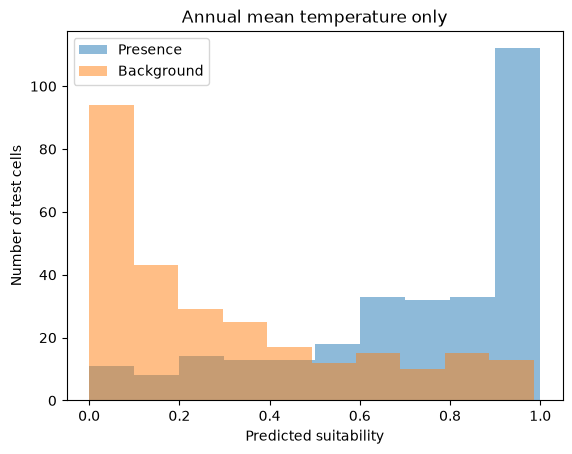

In [29]:
test_prediction = model.predict(X_test)
bio1_error = mean_absolute_error(y_test, test_prediction)
print("BIO1-only MAE:", round(bio1_error, 3))

plt.hist(test_prediction[y_test == 1], alpha=0.5, label="Presence")
plt.hist(test_prediction[y_test == 0], alpha=0.5, label="Background")
plt.xlabel("Predicted suitability")
plt.ylabel("Number of test cells")
plt.title("Annual mean temperature only")
plt.legend()
plt.show()

# MAE value = lower number, the better (percentage)
# If MAE was 0 it means it was a perfect prediction meaning the model was right everytime

**Discuss:** Do held-out presence cells generally receive higher scores than background cells? Why is setting aside records a better test than checking against the records used to train the model? Yes, the held-out presence cells generally score higher. If you gave a practice test and the final is the same as the practice test, that is the same as using the records that were used to train the model to test the model. 

## 13. Add two precipitation predictors

Temperature alone may miss conditions important for amphibians. Add:

* `bio_12`: annual precipitation (mm)
* `bio_15`: precipitation seasonality (variation in rainfall through the year)

Update `features` to select these three variables from the tables we already prepared. Keep the same training cells, test cells, background sample, and forest settings. That way we are comparing the effect of changing predictors.


In [41]:
features = ["bio_1", "bio_12", "bio_15"]

# Update the feature table and create a new test/train split
X = model_data[features]
# y = model_data["observed"] - we don't need to do this because y isn't changing, only X is because of the features

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=597,
)

three_variable_model = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=5, random_state=2,
)

#Fit the model to training data
three_variable_model.fit(X_train, y_train)

# Predict targets for test features
three_variable_prediction = three_variable_model.predict(X_test)

three_variable_error = mean_absolute_error(y_test, three_variable_prediction)

print("BIO1-only MAE:", round(bio1_error, 3))
print("BIO1 + BIO12 + BIO15 MAE:", round(three_variable_error, 3))


BIO1-only MAE: 0.285
BIO1 + BIO12 + BIO15 MAE: 0.261


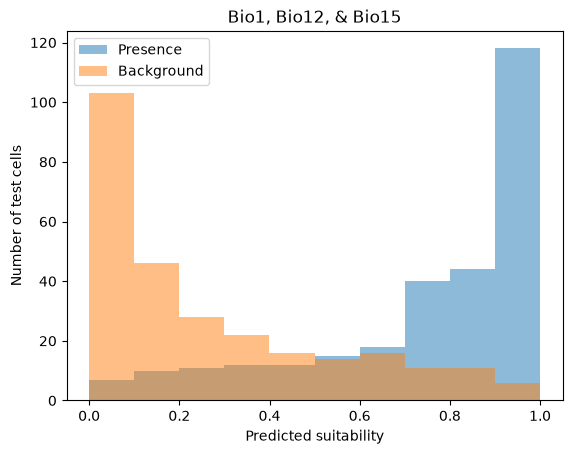

In [31]:
plt.hist(three_variable_prediction[y_test == 1], alpha=0.5, label="Presence")
plt.hist(three_variable_prediction[y_test == 0], alpha=0.5, label="Background")
plt.xlabel("Predicted suitability")
plt.ylabel("Number of test cells")
plt.title("Bio1, Bio12, & Bio15")
plt.legend()
plt.show()

**Interpretation:** Did adding precipitation reduce MAE? Give a biological reason why precipitation might help predict amphibian records. Adding predictors does not always improve predictions; what would a higher MAE tell us?

We are using the test cells for a planned classroom comparison. If we repeatedly tried many predictor combinations and chose the best score, we would need a fresh test set to evaluate that choice.

## 14. Make a suitability map

Use the three-variable model for our final map. After testing, fit a new forest with all modeling cells and predict across Maine. The earlier MAE describes the withheld-cell test, not a new test of this final model.


In [42]:
X = model_data[features]
final_model = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=5, random_state=597,
)
final_model.fit(X, y)
grid["suitability"] = final_model.predict(grid[features])


The following plotting recipe turns a table column back into a raster using its coordinates. `.reindex()` restores the original grid, including missing edge cells. You can reuse this recipe for other prediction columns.


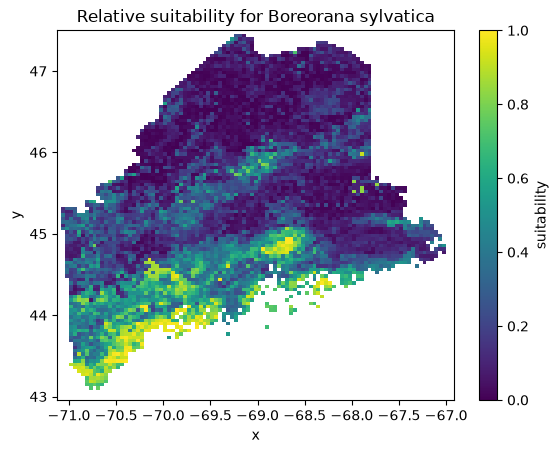

In [43]:
suitability = grid.set_index(["y", "x"])["suitability"].to_xarray()
suitability = suitability.reindex(y=climate.y, x=climate.x)

suitability.plot(vmin=0, vmax=1, cmap="viridis")
plt.title(f"Relative suitability for {target_species}")
plt.show()


## 15. Which variables did the forest use most?

The forest provides a simple importance score for each predictor. Higher values mean a variable contributed more to reducing error during tree building. The scores sum to 1.

This describes how the model used its **training data**. It does not prove that a variable causes the species' distribution. Predictors containing similar information can share importance.


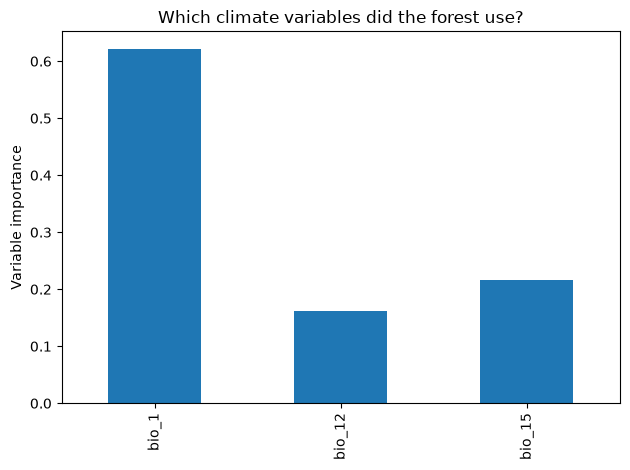

In [44]:
importance = pd.Series(final_model.feature_importances_, index=features)
importance.plot.bar()
plt.ylabel("Variable importance")
plt.title("Which climate variables did the forest use?")
plt.tight_layout()
plt.show()


## 16. Save your suitability map

Use the same raster export method as last week. The supplied climate grid uses WGS84 longitude and latitude (`EPSG:4326`).


In [45]:
suitability = suitability.rio.write_crs("EPSG:4326")
suitability.rio.to_raster("Lab07_suitability.tif")


## Wrap-up

1. What do `.fit()` and `.predict()` do?
2. Why do we keep the same test cells when comparing predictor sets?
3. How did MAE change when we added precipitation? What might explain that result?
4. What does variable importance tell us, and what does it not establish?
5. Why is our score not a probability that the species occurs at a location?

For the assignment, repeat this comparison for another species and explain the results in biological terms.

## References

* [Scikit-learn random forest documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html)
* [WorldClim bioclimatic variables](https://www.worldclim.org/data/bioclim.html)
